# EXP-004：以統計檢定驗證公平性（對照組）

> 實驗紀錄與結論：[EXP-004-statistical-validation.md](EXP-004-statistical-validation.md)

這份 notebook 讀取模擬產生的**原始數據**（每個 run、每個人的月結算），以 Python 的 `numpy`／`scipy`
**重新計算**所有統計量，不使用專案中自己實作的 `scripts/stats.ts`。目的有三：

1. **Cross-validation**：確認 `stats.ts`（手刻的 chi-square、Gini、Mann-Whitney U）與 `scipy` 的結果一致。
2. **視覺化**：以圖表呈現與對照組的比較、chi-square 檢定與消融實驗的結果。
3. **更嚴謹的檢定**：EXP-004 的 subgroup analysis 把同一個 run 裡的人視為獨立樣本；
   這裡改以 seed 為獨立單位重新檢定（第 6 節）。

## 重現方式

```bash
npm ci
npm run experiment -- scripts/experiments/exp-004-statistical-validation.ts   # 產生 data/exp-004/（約 5 分鐘）
python -m venv .venv && .venv/Scripts/pip install -r docs/experiments/requirements.txt   # macOS/Linux：.venv/bin/pip
.venv/Scripts/jupyter nbconvert --to notebook --execute --inplace docs/experiments/EXP-004-statistical-validation.ipynb
```

所有亂數皆由 seed 決定：相同程式碼必定產生位元組完全相同的 CSV，CI 會重新產生並比對（見 `.github/workflows/reproduce.yml`）。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from nbutils import AQUA, BLUE, INK, MUTED, ORANGE, VIOLET, gini, load, mw

scenarios = load("exp-004", "scenarios")
persons = load("exp-004", "persons")
runs = load("exp-004", "runs")
tests = load("exp-004", "tests")

COLOR = {"current": BLUE, "random": ORANGE, "noGray": AQUA, "ratioJitter": VIOLET}
LABEL = {"current": "Current", "random": "Random control", "noGray": "No gray fairness (pre EXP-001)",
         "ratioJitter": "Ratio jitter (pre EXP-002)"}

FAIR = scenarios.loc[~scenarios.structural, "scenario"].tolist()  # 非結構性情境
print(f"persons: {len(persons):,} rows, runs: {len(runs):,} rows, seeds: {runs.seed.nunique()}")
scenarios[["scenario", "desc", "structural", "n_people", "n_leaders"]]

persons: 30,300 rows, runs: 1,170 rows, seeds: 30


,scenario,desc,structural,n_people,n_leaders
0,S1,30 人（哨長 18／僅槍兵 12），每天 20% 隨機休假,False,30,18
1,S2,12 人（7／5），每天 10% 隨機休假,False,12,7
2,S3,50 人（27／23），每天 30% 隨機休假,False,50,27
3,S4,8 人（5／3），全月無休，正好是最低門檻,True,8,5
4,S5,10 人（6／4），全月無休,True,10,6
5,S6,20 人但只有 4 位哨長（哨長全勤，僅槍兵 20% 休假）,True,20,4
6,S7,20 人全部具哨長資格，20% 休假（無資格限制）,False,20,20
7,S8,30 人（18／12），平日 10% 休假、週末 60% 休假,False,30,18
8,S9,25 人（15／10），其中 7 人各休 10 天長假（時段錯開），其餘 10% 休假,False,25,15
9,S10,25 人（15／10），5 人第 16 天才報到、3 人第 11 天起離營,False,25,15


## 1. 硬性規定

`violations` 是獨立 checker（以小時計算歇哨、逐日檢查灰色時段，不使用排哨演算法的任何邏輯）找到的違規數。

In [2]:
v = runs.pivot_table(index="scenario", columns="variant", values="violations", aggfunc="sum").reindex(scenarios.scenario)
assert (v.fillna(0) == 0).all().all(), "發現違規！"
print("所有情境、所有版本、所有 seed 的違規數皆為 0")
v

所有情境、所有版本、所有 seed 的違規數皆為 0


variant,current,noGray,random,ratioJitter
scenario,,,,
S1,0.0,0.0,0.0,0.0
S2,0.0,0.0,0.0,0.0
S3,0.0,0.0,0.0,0.0
S4,0.0,NaN,NaN,NaN
S5,0.0,NaN,NaN,NaN
S6,0.0,NaN,NaN,NaN
S7,0.0,0.0,0.0,0.0
S8,0.0,0.0,0.0,0.0
S9,0.0,0.0,0.0,0.0


## 2. 從原始數據重算月結算，並與 `stats.ts` 比對

每個 run 中，第 *i* 人的應得節數 $E_i = w_i \cdot \frac{\sum_j s_j}{\sum_j w_j}$（$w$ = 上班天數、$s$ = 節數）。

- **偏差 RMS** $= \sqrt{\frac{1}{n}\sum_i (s_i - E_i)^2}$
- **Gini coefficient**：每人 $s_i / w_i$ 的不均程度
- **Chi-square goodness-of-fit**：`scipy.stats.chisquare(s, E)`，H0 為「節數依上班天數比例隨機分配」

In [3]:
# gini()、mw() 定義在 nbutils.py
def settle(g):
    g = g[g.work_days > 0]
    w, s, gr = g.work_days.to_numpy(float), g.shifts.to_numpy(float), g.gray.to_numpy(float)
    e, eg = w * s.sum() / w.sum(), w * gr.sum() / w.sum()
    chi = stats.chisquare(s, e)
    chig = stats.chisquare(gr, eg) if gr.sum() > 0 else None
    return pd.Series({
        "rms": np.sqrt(np.mean((s - e) ** 2)), "rms_gray": np.sqrt(np.mean((gr - eg) ** 2)),
        "gini": gini(s / w), "chi2": chi.statistic, "df": len(s) - 1, "p_upper": chi.pvalue,
        "dispersion": chi.statistic / (len(s) - 1),
        "chi2_gray": chig.statistic if chig else np.nan, "p_upper_gray": chig.pvalue if chig else np.nan,
    })

py = persons.groupby(["scenario", "variant", "seed"]).apply(settle, include_groups=False).reset_index()
both = runs.merge(py, on=["scenario", "variant", "seed"])

checks = {
    "rms": ("ts_rms", "rms"), "rms_gray": ("ts_rms_gray", "rms_gray"), "gini": ("ts_gini", "gini"),
    "chi2": ("ts_chi2", "chi2"), "p_upper": ("ts_p_upper", "p_upper"), "dispersion": ("ts_dispersion", "dispersion"),
    "chi2_gray": ("ts_chi2_gray", "chi2_gray"), "p_upper_gray": ("ts_p_upper_gray", "p_upper_gray"),
}
diff = pd.DataFrame({k: [(both[a] - both[b]).abs().max()] for k, (a, b) in checks.items()}, index=["max |stats.ts − scipy|"]).T
assert (diff.iloc[:, 0] < 1e-6).all(), diff
diff

,max |stats.ts − scipy|
rms,4.946799e-11
rms_gray,4.999112e-12
gini,4.957423e-13
chi2,4.916672e-10
p_upper,5.002665e-13
dispersion,4.859402e-11
chi2_gray,4.996892e-11
p_upper_gray,4.996004e-13


`stats.ts` 與 `scipy` 在 3,000 多個 run 上的最大差異都在 $10^{-6}$ 以下（CSV 以 12 位有效數字輸出）。
p-value 的差異來自 `stats.ts` 的 incomplete gamma 近似，遠小於判讀所需的精度。

接著比對 Mann-Whitney U test。`stats.ts` 使用 normal approximation、tie correction、**不做** continuity correction，
對應 `scipy.stats.mannwhitneyu(..., method="asymptotic", use_continuity=False)`。

> **這個比對曾經抓到一個 bug。** 第一次執行時 U 值最多差了 8.5（S12）：S12 是固定輪休，許多 run 的偏差在數學上完全相等，
> 但浮點誤差讓它們在小數點第 15 位以後不同，`stats.ts` 因此沒有把它們當作 tie。修正後兩邊都先四捨五入到 $10^{-9}$ 再排序，
> 報告中的 p-value 也已重新產生。詳見 [EXP-004](EXP-004-statistical-validation.md) 的更正紀錄。

In [4]:
rows = []
for t in tests.itertuples():
    cur = py[(py.scenario == t.scenario) & (py.variant == "current")].sort_values("seed")
    if t.comparison == "leader_vs_guard":
        g = persons[(persons.scenario == t.scenario) & (persons.variant == "current") & (persons.work_days > 0)]
        rate = g.shifts / g.work_days
        u, p = mw(rate[g.qualification == "leader"], rate[g.qualification == "guard"])
    else:
        alt = py[(py.scenario == t.scenario) & (py.variant == t.comparison.removeprefix("current_vs_"))].sort_values("seed")
        u, p = mw(cur[t.metric], alt[t.metric])
    rows.append({"scenario": t.scenario, "comparison": t.comparison, "metric": t.metric,
                 "U (stats.ts)": t.ts_u, "U (scipy)": u, "p (stats.ts)": t.ts_p, "p (scipy)": p})
mwc = pd.DataFrame(rows)
print("max |ΔU| =", (mwc["U (stats.ts)"] - mwc["U (scipy)"]).abs().max())
print("max |Δp| =", f'{(mwc["p (stats.ts)"] - mwc["p (scipy)"]).abs().max():.2e}')
assert (mwc["U (stats.ts)"] - mwc["U (scipy)"]).abs().max() < 1e-6
assert (mwc["p (stats.ts)"] - mwc["p (scipy)"]).abs().max() < 1e-6
mwc.head(8)

max |ΔU| = 0.0
max |Δp| = 1.37e-07


,scenario,comparison,metric,U (stats.ts),U (scipy),p (stats.ts),p (scipy)
0,S1,current_vs_random,rms,0.0,0.0,2.887424e-11,2.871949e-11
1,S1,current_vs_random,rms_gray,0.0,0.0,2.887424e-11,2.871949e-11
2,S1,current_vs_noGray,rms,557.0,557.0,1.136547e-01,1.136547e-01
3,S1,current_vs_noGray,rms_gray,0.0,0.0,2.887424e-11,2.871949e-11
4,S1,current_vs_ratioJitter,rms,0.0,0.0,2.887424e-11,2.871949e-11
5,S1,current_vs_ratioJitter,rms_gray,172.5,172.5,4.085172e-05,4.082947e-05
6,S1,leader_vs_guard,rate,98707.0,98707.0,6.298148e-01,6.298148e-01
7,S2,current_vs_random,rms,0.0,0.0,2.887424e-11,2.871949e-11


## 3. H1：現行版本 vs 隨機對照組

對照組（`randomOrder`）只遵守硬性規定，每次決策都把候選人隨機洗牌。兩者使用完全相同的出勤資料。
每個點是一個 seed 的月結算偏差 RMS（單位：節）。注意 y 軸是 log scale。

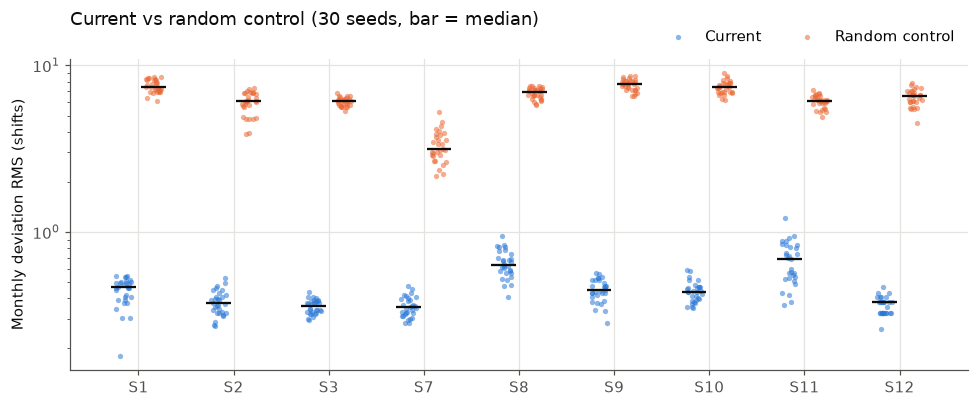

variant,current,random,ratio
scenario,,,
S1,0.44,7.53,16.97
S2,0.38,5.98,15.79
S3,0.36,6.05,16.92
S7,0.36,3.31,9.25
S8,0.65,6.81,10.45
S9,0.45,7.66,17.06
S10,0.44,7.41,16.84
S11,0.68,6.08,8.99
S12,0.36,6.44,17.73


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for k, var in enumerate(["current", "random"]):
    for i, sc in enumerate(FAIR):
        y = py[(py.scenario == sc) & (py.variant == var)].rms
        x = i + (k - 0.5) * 0.32 + np.random.default_rng(i).uniform(-0.08, 0.08, len(y))
        ax.scatter(x, y, s=12, color=COLOR[var], alpha=0.55, linewidths=0, label=LABEL[var] if i == 0 else None)
        ax.hlines(y.median(), i + (k - 0.5) * 0.32 - 0.13, i + (k - 0.5) * 0.32 + 0.13, color=INK, lw=1.5)
ax.set_yscale("log")
ax.set_xticks(range(len(FAIR)), FAIR)
ax.set_ylabel("Monthly deviation RMS (shifts)")
ax.set_title("Current vs random control (30 seeds, bar = median)", loc="left", color=INK, pad=22)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
plt.tight_layout()
plt.show()

h1 = (py[py.scenario.isin(FAIR)].groupby(["scenario", "variant"]).rms.mean().unstack()[["current", "random"]]
      .reindex(FAIR).assign(ratio=lambda d: d.random / d.current).round(2))
h1

### 單一 run 的樣子

S1（30 人）seed 1：橫軸是應得節數，縱軸是實際節數。落在對角線上 = 完全公平。

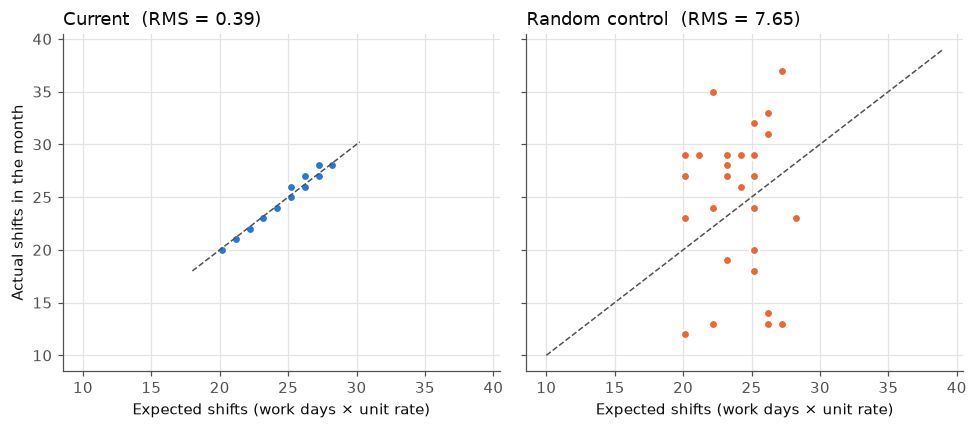

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, var in zip(axes, ["current", "random"]):
    g = persons[(persons.scenario == "S1") & (persons.variant == var) & (persons.seed == 1)]
    e = g.work_days * g.shifts.sum() / g.work_days.sum()
    lim = [min(e.min(), g.shifts.min()) - 2, max(e.max(), g.shifts.max()) + 2]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(e, g.shifts, s=36, color=COLOR[var], edgecolor="white", linewidth=1.5)
    rms = np.sqrt(np.mean((g.shifts - e) ** 2))
    ax.set_title(f"{LABEL[var]}  (RMS = {rms:.2f})", loc="left", color=INK)
    ax.set_xlabel("Expected shifts (work days × unit rate)")
axes[0].set_ylabel("Actual shifts in the month")
plt.tight_layout()
plt.show()

## 4. H2：Dispersion index 與 chi-square

Dispersion index = $\chi^2 / df$。若每一節都依上班天數比例「抽籤」決定（multinomial），期望值約為 1。

- 遠 **大於** 1：有人系統性被多排或少排。
- 遠 **小於** 1：分配比抽籤更平均，這是排班演算法想達成的效果。

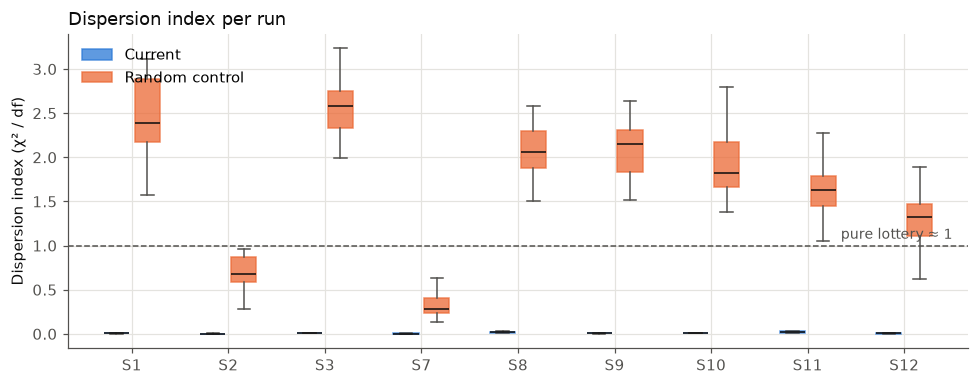

,dispersion_mean,chi2_not_rejected
scenario,,
S1,0.008881,1.0
S2,0.002713,1.0
S3,0.009349,1.0
S7,0.003875,1.0
S8,0.019506,1.0
S9,0.007920,1.0
S10,0.009188,1.0
S11,0.021711,1.0
S12,0.004103,1.0


In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for k, var in enumerate(["current", "random"]):
    d = [py[(py.scenario == sc) & (py.variant == var)].dispersion for sc in FAIR]
    pos = np.arange(len(FAIR)) + (k - 0.5) * 0.32
    bp = ax.boxplot(d, positions=pos, widths=0.26, patch_artist=True, showfliers=False,
                    medianprops={"color": INK}, whiskerprops={"color": MUTED}, capprops={"color": MUTED})
    for b in bp["boxes"]:
        b.set(facecolor=COLOR[var], edgecolor=COLOR[var], alpha=0.75)
    bp["boxes"][0].set_label(LABEL[var])
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.text(len(FAIR) - 0.5, 1.04, "pure lottery ≈ 1", ha="right", va="bottom", color=MUTED, fontsize=9)
ax.set_xticks(range(len(FAIR)), FAIR)
ax.set_ylabel("Dispersion index (χ² / df)")
ax.set_title("Dispersion index per run", loc="left", color=INK)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

h2 = (py[py.scenario.isin(FAIR) & (py.variant == "current")].groupby("scenario")
      .agg(dispersion_mean=("dispersion", "mean"), chi2_not_rejected=("p_upper", lambda p: (p >= 0.05).mean()))
      .reindex(FAIR))
h2

## 5. 消融實驗（Ablation study）

把現行版本的兩項改進各自拿掉，比較總節數與灰色時段的偏差。

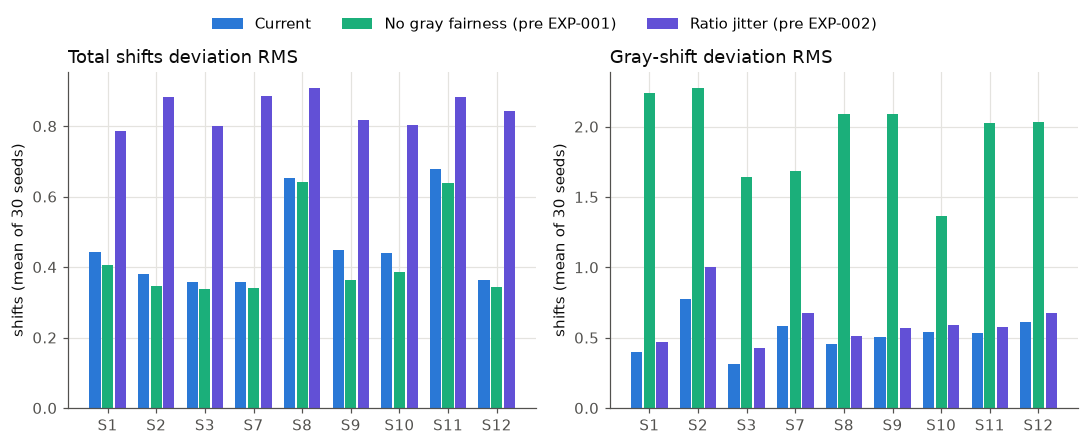

,scenario,removed,rms current,rms removed,p rms,gray current,gray removed,p gray,gaps current,gaps removed
0,S1,noGray,0.444,0.405,0.114,0.397,2.239,0.000,0.000,0.000
1,S1,ratioJitter,0.444,0.786,0.000,0.397,0.466,0.000,0.000,0.000
2,S2,noGray,0.379,0.346,0.065,0.778,2.273,0.000,2.233,1.200
3,S2,ratioJitter,0.379,0.881,0.000,0.778,0.999,0.000,2.233,2.467
4,S3,noGray,0.358,0.337,0.032,0.316,1.641,0.000,0.000,0.000
5,S3,ratioJitter,0.358,0.799,0.000,0.316,0.425,0.000,0.000,0.000
6,S7,noGray,0.358,0.341,0.231,0.581,1.682,0.000,0.000,0.000
7,S7,ratioJitter,0.358,0.885,0.000,0.581,0.678,0.003,0.000,0.000
8,S8,noGray,0.651,0.642,0.564,0.453,2.089,0.000,0.000,0.000
9,S8,ratioJitter,0.651,0.908,0.000,0.453,0.510,0.001,0.000,0.000


In [8]:
variants = ["current", "noGray", "ratioJitter"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=False)
for ax, metric, title in zip(axes, ["rms", "rms_gray"], ["Total shifts deviation RMS", "Gray-shift deviation RMS"]):
    m = py[py.scenario.isin(FAIR)].groupby(["scenario", "variant"])[metric].mean().unstack().reindex(FAIR)
    w = 0.26
    for k, var in enumerate(variants):
        ax.bar(np.arange(len(FAIR)) + (k - 1) * w, m[var], width=w - 0.03, color=COLOR[var], label=LABEL[var])
    ax.set_xticks(range(len(FAIR)), FAIR)
    ax.set_title(title, loc="left", color=INK)
    ax.set_ylabel("shifts (mean of 30 seeds)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.07))
plt.tight_layout()
plt.show()

abl = []
for sc in FAIR:
    cur = py[(py.scenario == sc) & (py.variant == "current")].sort_values("seed")
    for var in ["noGray", "ratioJitter"]:
        alt = py[(py.scenario == sc) & (py.variant == var)].sort_values("seed")
        gaps = runs[(runs.scenario == sc)].groupby("variant").gaps.mean()
        abl.append({"scenario": sc, "removed": var,
                    "rms current": cur.rms.mean(), "rms removed": alt.rms.mean(), "p rms": mw(cur.rms, alt.rms)[1],
                    "gray current": cur.rms_gray.mean(), "gray removed": alt.rms_gray.mean(),
                    "p gray": mw(cur.rms_gray, alt.rms_gray)[1],
                    "gaps current": gaps["current"], "gaps removed": gaps[var]})
pd.DataFrame(abl).round(3)

## 6. H3：哨長 vs 僅槍兵，以 seed 為獨立單位重新檢定

EXP-004 把所有 seed 的每個人合併成一個樣本做 Mann-Whitney U test。但同一個 run 裡的人**並不獨立**：
一個人多站一節，別人就少站一節。這違反了檢定的獨立性假設，p-value 不可靠。

這裡改用以 seed 為獨立單位的做法：

1. 每個 seed 算一個比值 $r = \overline{(s/w)}_{\text{哨長}} \,/\, \overline{(s/w)}_{\text{僅槍兵}}$，30 個 seed 得到 30 個彼此獨立的 $r$。
2. 以 **Wilcoxon signed-rank test** 檢定 $\log r$ 的中位數是否為 0（即 $r = 1$）。
3. 以 **bootstrap**（10,000 次，對 seed 重抽）估計 $r$ 平均的 95% CI。

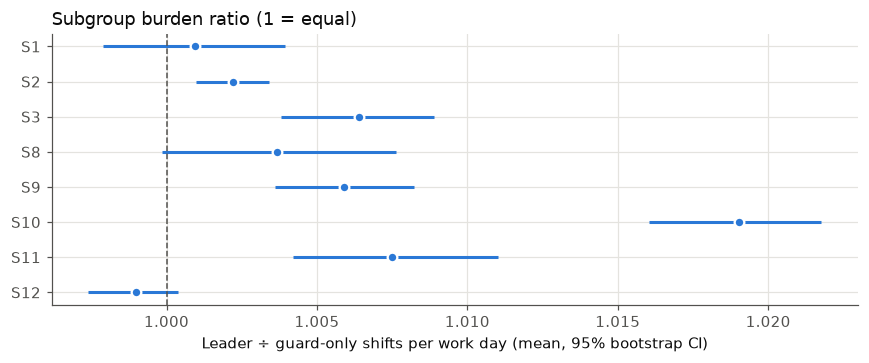

,mean ratio,CI low,CI high,Wilcoxon p (per seed),pooled MW p (EXP-004)
scenario,,,,,
S1,1.0010,0.9979,1.0039,0.3492,0.6298
S2,1.0022,1.0010,1.0034,0.0022,0.1883
S3,1.0064,1.0038,1.0089,0.0000,0.0001
S8,1.0037,0.9998,1.0076,0.1460,0.0612
S9,1.0059,1.0036,1.0082,0.0000,0.0010
S10,1.0190,1.0160,1.0218,0.0000,0.0000
S11,1.0075,1.0042,1.0110,0.0002,0.1254
S12,0.9990,0.9974,1.0004,0.8448,0.1619


In [9]:
cur = persons[(persons.variant == "current") & (persons.work_days > 0) & persons.scenario.isin(FAIR)].copy()
cur["rate"] = cur.shifts / cur.work_days
per_seed = cur.groupby(["scenario", "seed", "qualification"]).rate.mean().unstack()
per_seed = per_seed.dropna()  # S7 沒有僅槍兵
per_seed["ratio"] = per_seed.leader / per_seed.guard

boot_rng = np.random.default_rng(0)
rows = []
for sc, g in per_seed.groupby(level="scenario"):
    r = g.ratio.to_numpy()
    boots = boot_rng.choice(r, size=(10_000, len(r)), replace=True).mean(axis=1)
    pooled = mwc[(mwc.scenario == sc) & (mwc.comparison == "leader_vs_guard")]["p (scipy)"]
    rows.append({"scenario": sc, "mean ratio": r.mean(), "CI low": np.percentile(boots, 2.5),
                 "CI high": np.percentile(boots, 97.5), "Wilcoxon p (per seed)": stats.wilcoxon(np.log(r)).pvalue,
                 "pooled MW p (EXP-004)": pooled.iloc[0] if len(pooled) else np.nan})
h3 = pd.DataFrame(rows).set_index("scenario").reindex([s for s in FAIR if s in per_seed.index.get_level_values(0)])

fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(h3))[::-1]
ax.hlines(y, h3["CI low"], h3["CI high"], color=COLOR["current"], lw=2)
ax.scatter(h3["mean ratio"], y, s=40, color=COLOR["current"], edgecolor="white", linewidth=1.5, zorder=3)
ax.axvline(1, color=MUTED, lw=1, ls="--")
ax.set_yticks(y, h3.index)
ax.set_xlabel("Leader ÷ guard-only shifts per work day (mean, 95% bootstrap CI)")
ax.set_title("Subgroup burden ratio (1 = equal)", loc="left", color=INK)
plt.tight_layout()
plt.show()
h3.round(4)

In [10]:
sig_pooled = set(h3.index[h3["pooled MW p (EXP-004)"] < 0.05])
sig_seed = set(h3.index[h3["Wilcoxon p (per seed)"] < 0.05])
print("EXP-004（合併每人）顯著的情境：", sorted(sig_pooled, key=FAIR.index))
print("以 seed 為單位仍顯著的情境：  ", sorted(sig_seed, key=FAIR.index))
print(f"最大效果量：{(h3['mean ratio'] - 1).abs().max() * 100:.1f}%")

EXP-004（合併每人）顯著的情境： ['S3', 'S9', 'S10']
以 seed 為單位仍顯著的情境：   ['S2', 'S3', 'S9', 'S10', 'S11']
最大效果量：1.9%


**結果與預期相反。** 原本預期以 seed 為單位會比較保守、顯著的情境變少；實際上反而變多。
原因是每個 seed 先取平均後，人與人之間的差異（變異的主要來源）被抵銷，剩下的「哨長 vs 僅槍兵」差距在 30 個 seed 間非常一致，
檢定力（power）因此提高。

結論：哨長負擔略高是**穩定存在**的系統性偏差，比 EXP-004 原本的判斷更明確；但效果量仍然很小（最大 1.9%，S10 約每月 0.6 節）。

## 7. 結論

這份 notebook 中所有數字都在上方程式碼執行時，從 `data/*.csv` 重新計算；解讀與後續決策記錄在
[EXP-004](EXP-004-statistical-validation.md)。

In [11]:
summary = pd.DataFrame({
    "RMS current": h1.current, "RMS random": h1.random, "random ÷ current": h1.ratio,
    "dispersion (current)": h2.dispersion_mean, "χ² not rejected": h2.chi2_not_rejected,
}).join(h3[["mean ratio", "Wilcoxon p (per seed)"]].rename(columns={"mean ratio": "leader ÷ guard"}))
summary.round(3)

,RMS current,RMS random,random ÷ current,dispersion (current),χ² not rejected,leader ÷ guard,Wilcoxon p (per seed)
scenario,,,,,,,
S1,0.44,7.53,16.97,0.009,1.0,1.001,0.349
S2,0.38,5.98,15.79,0.003,1.0,1.002,0.002
S3,0.36,6.05,16.92,0.009,1.0,1.006,0.000
S7,0.36,3.31,9.25,0.004,1.0,NaN,NaN
S8,0.65,6.81,10.45,0.020,1.0,1.004,0.146
S9,0.45,7.66,17.06,0.008,1.0,1.006,0.000
S10,0.44,7.41,16.84,0.009,1.0,1.019,0.000
S11,0.68,6.08,8.99,0.022,1.0,1.007,0.000
S12,0.36,6.44,17.73,0.004,1.0,0.999,0.845
